# Forecasting a noisy sensor series

Do recurrent cells improve one-step prediction over a persistence baseline?

I compare RNN, GRU and LSTM on a controlled periodic sensor signal. The chronological split and train-only normalization make the temporal evaluation explicit.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "05_recurrent_forecasting"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Chronological windows

The signal is synthetic and has two periodic components plus Gaussian noise. Splits are created on the raw timeline before windows are constructed, so no input window crosses a split boundary. This strict convention discards the first 24 targets in each region.

[1056, 336, 336]


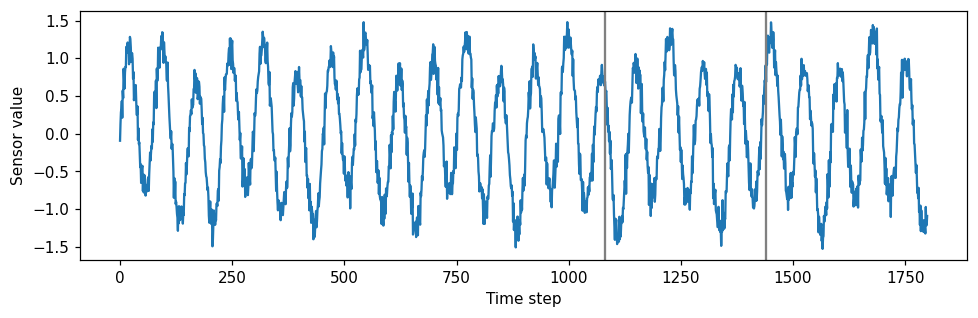

In [5]:
from deep_projects.models import RecurrentForecaster

rng = np.random.default_rng(1031)
time = np.arange(1800)
series = np.sin(time / 12) + 0.3 * np.sin(time / 37) + rng.normal(0, 0.12, len(time))
mean, scale = series[:1080].mean(), series[:1080].std()
normalized = (series - mean) / scale


def windows(region):
    inputs = np.stack([region[index - 24 : index] for index in range(24, len(region))])
    targets = region[24:, None]
    return TensorDataset(
        torch.tensor(inputs[..., None], dtype=torch.float32),
        torch.tensor(targets, dtype=torch.float32),
    )


data = DataSplit(
    windows(normalized[:1080]),
    windows(normalized[1080:1440]),
    windows(normalized[1440:]),
)
train_loader, validation_loader, test_loader = data.loaders()
print([len(dataset) for dataset in [data.train, data.validation, data.test]])
plt.figure(figsize=(9, 3))
plt.plot(series)
plt.axvline(1080, color="gray")
plt.axvline(1440, color="gray")
plt.xlabel("Time step")
plt.ylabel("Sensor value")
plt.tight_layout()
plt.savefig(output / "series.png", dpi=140)
plt.show()

## Cell comparison

The model predicts from the last hidden output. RNN has a single recurrent state; GRU and LSTM add gates. Gradient clipping limits extreme update norms. The architecture is selected using validation MSE.

class RecurrentForecaster(nn.Module):
    def __init__(self, cell="gru", hidden=24):
        super().__init__()
        recurrent = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.recurrent = recurrent(1, hidden, batch_first=True)
        self.readout = nn.Linear(hidden, 1)

    def forward(self, windows):
        sequence, _ = self.recurrent(windows)
        return self.readout(sequence[:, -1])



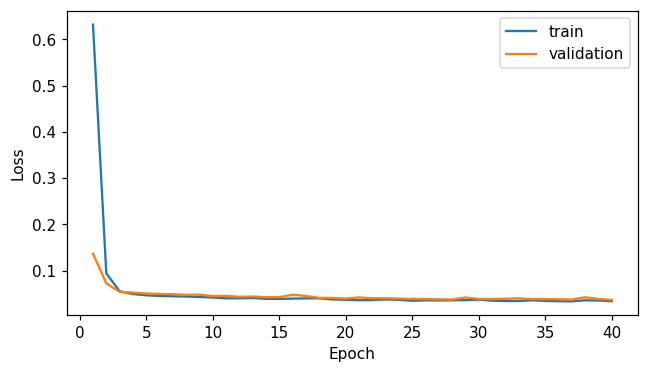

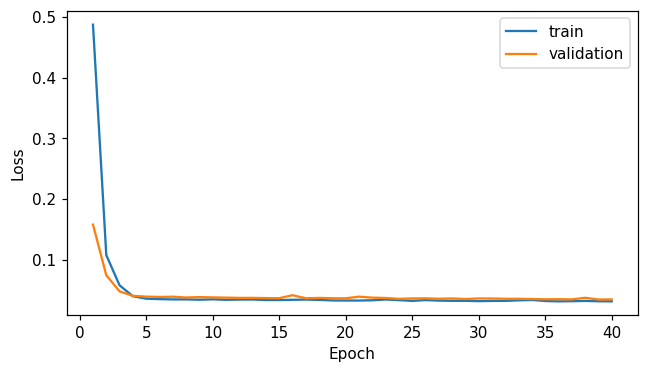

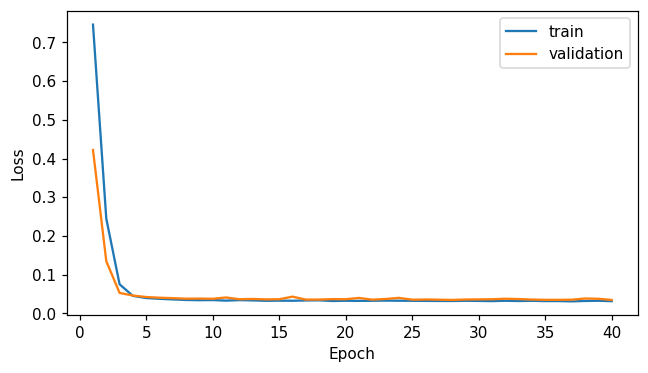

   cell  validation_mse  parameters
0   rnn        0.036999         673
1   gru        0.034615        1969
2  lstm        0.034676        2617 gru


In [7]:
print(inspect.getsource(RecurrentForecaster))
models, rows = {}, []
for cell in ["rnn", "gru", "lstm"]:
    seed_everything()
    model = RecurrentForecaster(cell)
    train_loader, validation_loader, test_loader = data.loaders()
    history = Trainer(model, nn.MSELoss(), TrainConfig(epochs=EPOCHS)).fit(
        train_loader, validation_loader
    )
    plot_history(history, output / f"{cell}_loss.png")
    predicted, targets = predict(model, validation_loader)
    rows.append(
        {
            "cell": cell,
            "validation_mse": float(F.mse_loss(predicted, targets)),
            "parameters": sum(p.numel() for p in model.parameters()),
        }
    )
    models[cell] = model
selected = min(rows, key=lambda row: row["validation_mse"])["cell"]
model = models[selected]
print(pd.DataFrame(rows), selected)

## Persistence and test predictions

Persistence copies the final observed value. Errors are converted back to the raw sensor scale. Forecasts are one step ahead with observed inputs; this does not evaluate recursively generated multi-step forecasts.

{'synthetic': True, 'validation': [{'cell': 'rnn', 'validation_mse': 0.036998532712459564, 'parameters': 673}, {'cell': 'gru', 'validation_mse': 0.03461459279060364, 'parameters': 1969}, {'cell': 'lstm', 'validation_mse': 0.03467561677098274, 'parameters': 2617}], 'selected': 'gru', 'test_rmse': 0.13761916756629944, 'persistence_rmse': 0.1890445053577423}


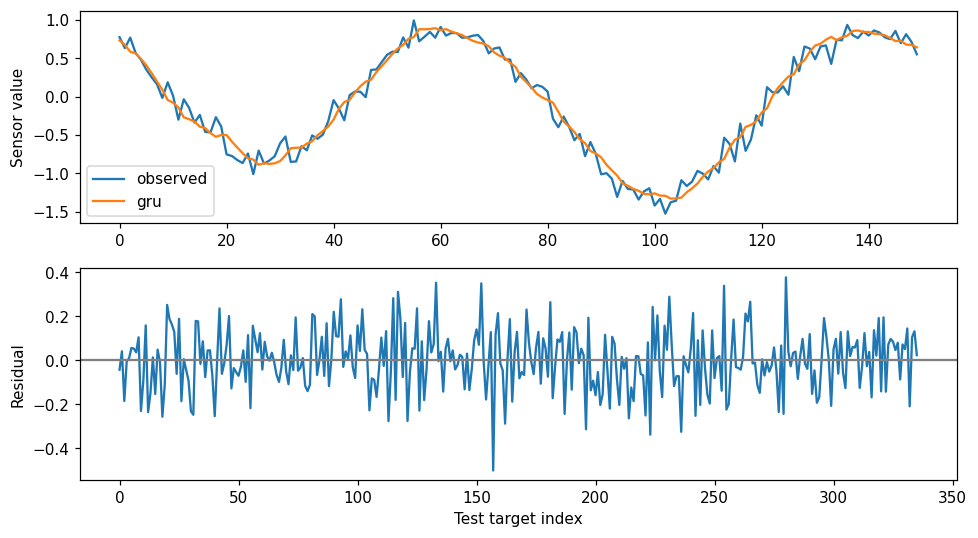

In [9]:
predicted, targets = predict(model, test_loader)
persistence = data.test.tensors[0][:, -1]
results = {
    "synthetic": True,
    "validation": rows,
    "selected": selected,
    "test_rmse": float(F.mse_loss(predicted, targets).sqrt() * scale),
    "persistence_rmse": float(F.mse_loss(persistence, targets).sqrt() * scale),
}
print(results)
fig, axes = plt.subplots(2, 1, figsize=(9, 5))
axes[0].plot(targets[:150, 0] * scale + mean, label="observed")
axes[0].plot(predicted[:150, 0] * scale + mean, label=selected)
axes[0].legend()
axes[1].plot((predicted - targets)[:, 0] * scale)
axes[1].axhline(0, color="gray")
axes[0].set(ylabel="Sensor value")
axes[1].set(xlabel="Test target index", ylabel="Residual")
fig.tight_layout()
fig.savefig(output / "forecast.png", dpi=140)
plt.show()

## Reading the result

A periodic synthetic series is useful for checking sequence models and temporal leakage. It does not establish performance on wearable or clinical signals. Persistence is a necessary reference because slowly varying signals can be predictable without a recurrent model.

In [11]:
result_path = root / "results" / "05_recurrent_forecasting.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/05_recurrent_forecasting.json


## Next experiment

Evaluate multi-step forecasts with recursive inputs and compare horizons. Add an abrupt frequency shift in a predefined test segment to inspect distribution change.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_5. [HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week03_architectures.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.